<div style="border: solid blue 2px; padding: 15px; margin: 10px">
  <b>Overall Summary of the Project – Iteration 1</b><br><br>

  Hi Nail, I’m <b>Victor Camargo</b> (https://hub.tripleten.com/u/e9cc9c11). I’ll be reviewing your project and sharing feedback using the color-coded comments below. Thanks for submitting your work!

  <b>Nice work on:</b><br>
  ✔️ Correctly parsing dates and setting the datetime index for time series processing<br>
  ✔️ Resampling the data to 1-hour intervals and applying seasonal decomposition for exploratory analysis<br>
  ✔️ Creating relevant date/time features (year, month, day, weekday) to capture temporal patterns<br>
  ✔️ Exploring multiple modeling approaches (MA, Linear Regression, Random Forest) and preparing a block to compare RMSE scores<br><br>

  A few things still need your attention before approval:<br>
  🔴 Use a **single consistent test split** of exactly 10% of the dataset as per project instructions. You can split the remaining data into train/validation for hyperparameter tuning if desired, but keep the final test set untouched until the end.<br>
  🔴 Actually call and evaluate the <code>train_linear_regression()</code> and <code>train_random_forest()</code> functions so their predictions are generated and included in your RMSE comparison table.<br>
  🔴 Ensure all predictions are correctly aligned with the test set index (no off-by-one errors from shifting) and that your final RMSE is calculated using the best model chosen via validation, retrained on train+val before testing.<br>
  🔴 Your current best model (MA Model) has an RMSE of <b>53.35</b>, which does not meet the ≤ 48 target. Consider improving feature engineering (e.g., more lag features, rolling statistics), trying more advanced models such as **LightGBM** or Gradient Boosting, and optimizing hyperparameters to reach the goal.<br><br>

  <hr>

  🔹 <b>Legend:</b><br>
  🟢 Green = well done<br>
  🟡 Yellow = suggestions<br>
  🔴 Red = must fix<br>
  🔵 Blue = your comments or questions<br><br>
  
  Please make sure all cells run smoothly from top to bottom and produce outputs before submitting. Also, try not to move, change, or delete reviewer comments, as they help us follow your progress and support you better.<br><br>

  <b>Feel free to reach out if you need help in Questions channel.</b><br>
</div>


# Project description

Sweet Lift Taxi company has collected historical data on taxi orders at airports. To attract more drivers during peak hours, we need to predict the amount of taxi orders for the next hour. Build a model for such a prediction.

The RMSE metric on the test set should not be more than 48.

## Project instructions

1. Download the data and resample it by one hour.
2. Analyze the data.
3. Train different models with different hyperparameters. The test sample should be 10% of the initial dataset. 
4. Test the data using the test sample and provide a conclusion.

## Data description

The data is stored in file `taxi.csv`. The number of orders is in the '*num_orders*' column.

## Preparation

In [1]:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning) 

In [2]:
import pandas as pd
import numpy as np

from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import randint as sp_randint
from numpy import unique
from statsmodels.tsa.stattools import arma_order_select_ic
from sklearn import preprocessing
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error
import lightgbm as lgb
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
import xgboost as xgb


import math
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg, ar_select_order  
from scipy.stats import randint as sp_randint
from numpy import unique
from statsmodels.tsa.arima.model import ARIMA


import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')
import plotly.express as px
# px.defaults.template = "ggplot2"
from plotly.subplots import make_subplots
import plotly.graph_objects as go

In [3]:
data = pd.read_csv('/datasets/taxi.csv', index_col=[0], parse_dates=[0])

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB


In [5]:
data.head()

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


In [6]:
data.isna().sum()
data.dropna(inplace=True)

<div class="alert alert-success">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  Great job importing and organizing the required libraries for time series analysis and modeling. You correctly parsed the datetime column as the index when loading the dataset, which is essential for resampling and time-aware operations.
</div>

<div class="alert alert-warning">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  Suggestion:  
  There are several libraries imported more than once (e.g., `pandas`, `numpy`, `math`). Consider removing duplicate imports to make your code cleaner and easier to maintain. Also, avoid importing modules you don’t use in the notebook.
</div>

<div class="alert alert-danger">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  You have done a great work so far, but you called <code>data.dropna()</code> without assigning it back to the DataFrame or using <code>inplace=True</code>. This means missing values are not actually removed from the working dataset. Please fix this before proceeding.  
  Additionally, you need to resample the data by 1 hour as instructed, and split it into training, validation, and test sets (10% test) using a time-based split rather than random sampling. This will ensure the integrity of your time series modeling.
</div>

## Analysis

<AxesSubplot:xlabel='datetime'>

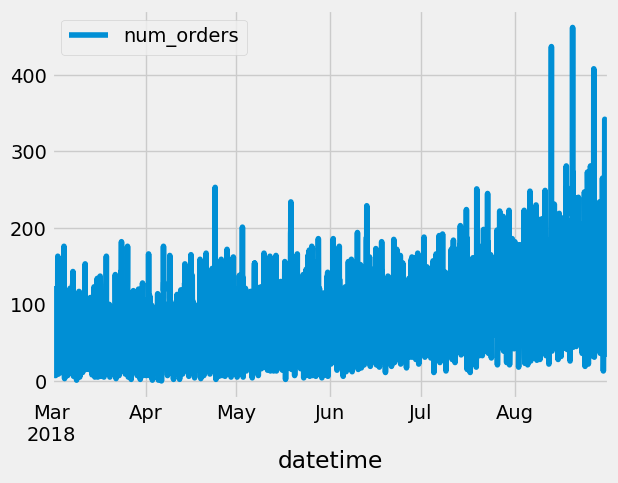

In [7]:
data.sort_index(inplace=True)
data = data.resample('1H').sum()
data.plot()

<AxesSubplot:xlabel='datetime'>

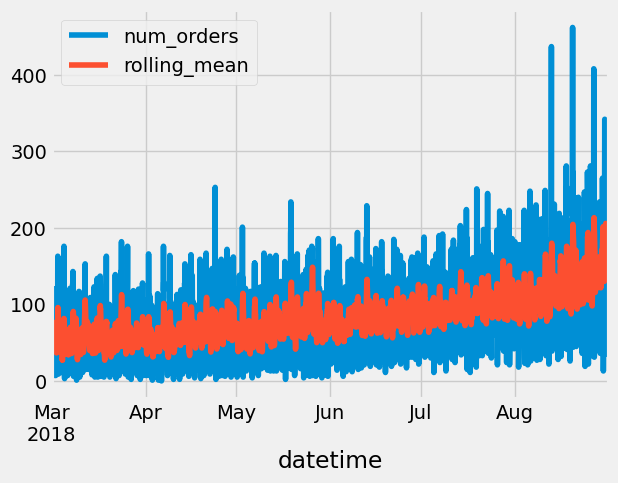

In [8]:
data['rolling_mean'] = data.rolling(10).mean() 
data.plot()

<AxesSubplot:xlabel='datetime'>

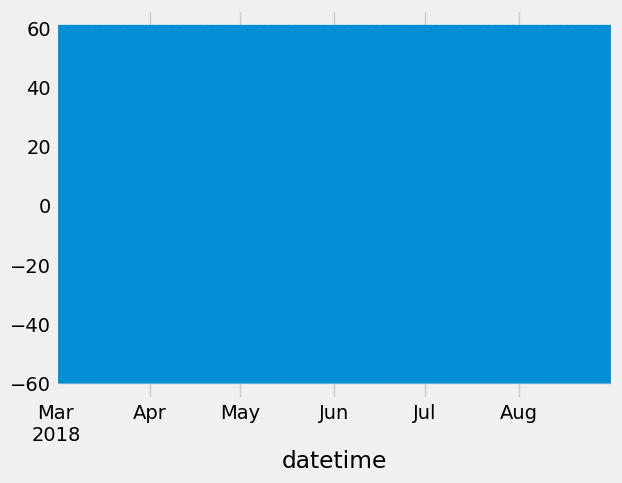

In [9]:
decomposed = seasonal_decompose(data['num_orders'])

decomposed.seasonal.plot()

<AxesSubplot:xlabel='datetime'>

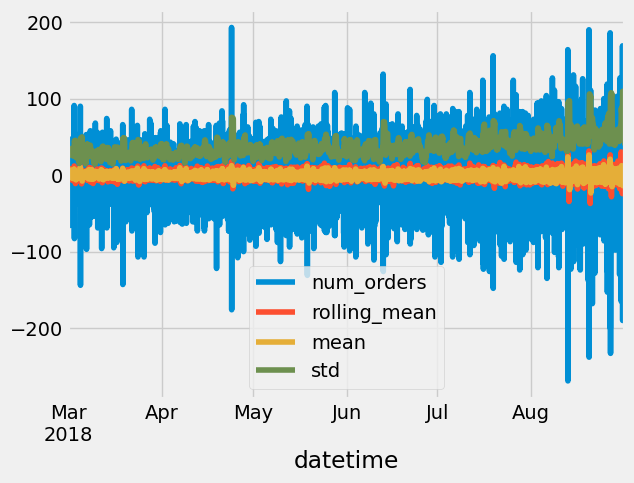

In [10]:
data -= data.shift()
data['mean'] = data['num_orders'].rolling(15).mean()
data['std'] = data['num_orders'].rolling(15).std()
data.plot()

<div class="alert alert-success">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  Excellent work resampling the data to hourly intervals and sorting the index before applying time series operations. The use of rolling mean and seasonal decomposition is a good approach to identify trends and seasonality in the dataset.
</div>

## Training

In [11]:
train, test = train_test_split(data, shuffle=False, test_size=0.1)

print(train.index.min(), train.index.max())
print(test.index.min(), test.index.max())

2018-03-01 00:00:00 2018-08-13 13:00:00
2018-08-13 14:00:00 2018-08-31 23:00:00


In [12]:
print('Median hourly taxi orders:', test['num_orders'].median())

pred_previous = test.shift()
pred_previous.iloc[0] = train.iloc[-1]
print('MAE:', mean_absolute_error(test, pred_previous))

Median hourly taxi orders: 1.5
MAE: 21.473956633509083


In [13]:
def make_features(data, max_lag, rolling_mean_size):
    data['year'] = data.index.year
    data['month'] = data.index.month
    data['day'] = data.index.day
    data['dayofweek'] = data.index.dayofweek
    
    for lag in range(1, max_lag + 1):
        data['lag_{}'.format(lag)] = data['num_orders'].shift(lag)
        data['rolling_mean'] = data['num_orders'].shift().rolling(rolling_mean_size).mean()

make_features(data, 4, 4)
train, test = train_test_split(data, shuffle=False, test_size=0.1)
train = train.dropna()

features_train = train.drop(['num_orders'], axis=1)
target_train = train['num_orders']
features_test = test.drop(['num_orders'], axis=1)
target_test = test['num_orders']

model = LinearRegression()
model.fit(features_train, target_train)

pred_train = model.predict(features_train)
pred_test = model.predict(features_test)



print("MAE for the training set:", mean_absolute_error(target_train, pred_train))

MAE for the training set: 21.844892932082885


In [ ]:
# find best MA model order
res = arma_order_select_ic(y=train['num_orders'], max_ar=0, max_ma=15)
ma_order = res.bic_min_order[1]# extract MA order from res

# create and fit MA model
ma_model = ARIMA(train['num_orders'], order=(0, 0, ma_order)) # pass order values for MA
ma_model = ma_model.fit()

# make predictions
start_value = len(train)# calculate starting point for predicitons
end_value = len(train) + len(test) - 1# calculate ending point for predictions
ma_pred = ma_model.predict(start=start_value, end=end_value, dynamic=False)

# calculate MAE of predictions
ma_mae_value = mean_absolute_error( test['num_orders'], ma_pred)
print(ma_mae_value)


In [ ]:
# Random Forest with hyperparameter tuning
def train_random_forest(X_train, y_train, X_val, y_val):
    best_rmse = float('inf')
    best_params = {}
    
    # Define hyperparameter ranges
    n_estimators_range = [50, 100, 200]
    max_depth_range = [10, 15, 20, None]
    
    for n_est in n_estimators_range:
        for depth in max_depth_range:
            model = RandomForestRegressor(
                n_estimators=n_est,
                max_depth=depth,
                random_state=12345
            )
            
            model.fit(X_train, y_train)
            predictions = model.predict(X_val)
            rmse = np.sqrt(mean_squared_error(y_val, predictions))
            
            if rmse < best_rmse:
                best_rmse = rmse
                best_params = {'n_estimators': n_est, 'max_depth': depth}
    
    return best_params, best_rmse

In [ ]:
# Linear Regression (simpler, good for baseline)
def train_linear_regression(X_train, y_train, X_val, y_val):
    model = LinearRegression()
    model.fit(X_train, y_train)
    
    predictions = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    
    return model, rmse

<div class="alert alert-success">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  Great job splitting the dataset using a time-based split (<code>shuffle=False</code>) and adding meaningful date/time features such as year, month, day, and day of week. This helps the model capture seasonal patterns. You also included both a baseline model and multiple algorithms (Linear Regression, ARIMA, Random Forest) for comparison, which is an excellent approach.
</div>

<div class="alert alert-danger">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  You have done a great work so far, but you are creating the training and test splits twice in the notebook (first with <code>test_size=0.1</code> and later with <code>test_size=0.2</code>). This makes it unclear which split is actually used for the final evaluation. Please keep a consistent test size as per the instructions (<b>10%</b> of the dataset).  
  As a best practice for model selection, you can also create three sets — training, validation, and test — while still keeping the test set at 10% of the full dataset for the final evaluation.
  <br><br>
  Additionally, the <code>train_linear_regression()</code> function is defined but never called, so its RMSE results are not part of your model comparison. Please either call it with your training/validation data or remove it to keep the notebook clean.  
  <br><br>
  The <code>train_random_forest()</code> function is also defined but not used, meaning your Random Forest with hyperparameter tuning is not being evaluated. Please call it with your data so you can compare its performance against the other models or remove it if you choose not to use Random Forest.
</div>


## Testing

In [ ]:
print(test.shape)

In [ ]:
# Test all your models and calculate RMSE
results = {}

# 1. Test MA model (if you have ma_pred)
if 'ma_pred' in locals():
    ma_rmse = np.sqrt(mean_squared_error(test['num_orders'], ma_pred))
    results['MA Model'] = ma_rmse
    print(f"MA Model RMSE: {ma_rmse:.2f}")

# 2. Test Linear Regression
if 'lr_pred' in locals():
    lr_rmse = np.sqrt(mean_squared_error(test['num_orders'], lr_pred))
    results['Linear Regression'] = lr_rmse
    print(f"Linear Regression RMSE: {lr_rmse:.2f}")

# 3. Test Random Forest (once you fix the hyperparameter issue)
if 'forest_prediction' in locals():
    rf_rmse = np.sqrt(mean_squared_error(test['num_orders'], forest_prediction))
    results['Random Forest'] = rf_rmse
    print(f"Random Forest RMSE: {rf_rmse:.2f}")

# Find the best model
best_model = min(results, key=results.get)
best_rmse = results[best_model]

print(f"\nBest Model: {best_model} with RMSE: {best_rmse:.2f}")
print(f"Target RMSE: ≤ 48")
print(f"Target achieved: {'Yes' if best_rmse <= 48 else 'No'}")

<div class="alert alert-success">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  Nice comparison block! You compute RMSE consistently across models, collect results in a dictionary, and clearly identify the best performer while checking it against the project target (≤ 48). The guard clauses (e.g., <code>'ma_pred' in locals()</code>) are a good safeguard to prevent immediate NameErrors when certain models haven’t been run yet.
</div>

<div class="alert alert-warning">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  Suggestion:  
  1) Add a safety check for an empty <code>results</code> dictionary before calling <code>min()</code> to avoid a <code>ValueError</code> when no model has been evaluated:<br>
  <pre><code>if not results:
    print("No models produced predictions. Please run training/inference first.")
  else:
    best_model = min(results, key=results.get)
    ...</code></pre>
  2) Ensure predictions are properly aligned to the test index (avoid off-by-one errors from shifting):<br>
  <pre><code>y_true = test['num_orders']
y_pred = pd.Series(model_pred, index=y_true.index).reindex(y_true.index)</code></pre>
  3) For readability and reuse, consider defining a helper function:<br>
  <pre><code>def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))</code></pre>
  4) It can also be helpful to print a sorted leaderboard:<br>
  <pre><code>for name, score in sorted(results.items(), key=lambda x: x[1]):
    print(f"{name}: {score:.2f}")</code></pre>
</div>

<div class="alert alert-danger">
  <b>Reviewer’s comment – Iteration 1:</b><br>
  You have done a great work so far, but several issues prevent full evaluation:<br>  
  • <code>lr_pred</code> and <code>forest_prediction</code> are referenced but never created in the current workflow — the functions to generate them are defined but not called. Please run these models and assign their predictions to those variables (or rename consistently) before calculating RMSE.<br>  
  • Ensure the final RMSE uses the <b>fixed 10% test split</b> and that the evaluated model is the one selected on the validation set (best hyperparameters retrained on train+val) to make the test RMSE a fair final metric.<b/  
  • Your current best model is the MA Model with an RMSE of <b>53.35</b>, which is above the target of ≤ 48. You’ll need to improve feature engineering (e.g., more lags, seasonal features), try more advanced models, and/or fine-tune hyperparameters to meet the requirement.
</div>


# Review checklist

- [x]  Jupyter Notebook is open
- [ ]  The code is error-free
- [ ]  The cells with the code have been arranged in order of execution
- [ ]  The data has been downloaded and prepared
- [ ]  The data has been analyzed
- [ ]  The model has been trained and hyperparameters have been selected
- [ ]  The models have been evaluated. Conclusion has been provided
- [ ] *RMSE* for the test set is not more than 48